# PULSE-A Power Analysis (timestep engine)

**Updated to the `new_mission_power_simulation` engine.** Everything in this notebook now runs on the STK timestep model:

* real elapsed time, real `dt` per row, real `InShadow` flag, real `OrbitNumberBounded` (no 90 / 55 / 35-minute assumption)
* generation = difference of the cumulative STK column (auto-detected; `E = P·dt` is used if a file holds instantaneous power)
* consumption = `P_state · dt`, with state powers imported from `Basic PB Calculator.py`
* `SOC_i = clip(SOC_{i-1} + E_gen,i − E_cons,i, 0, 95 %)`

Sections 1–4 are the original analyses (threshold, anomaly, consumption by state, solar statistics) re-done on the timestep output.
Section 5 is new: the evidence behind the **Orbit / Insertion Requirements** slide (altitude, inclination, eccentricity, insertion date, handover-to-deployment time).

In [1]:
from __future__ import annotations

import importlib
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 0. PATH SETUP
# ==========================================
# Run this notebook from the "PULSE-A Timestep Sim" folder. Data files and
# Basic PB Calculator.py are found automatically in this folder or the parent
# "Orbital Power Budget Sim" folder (including _ORGANIZED/...).
# The engine (new_mission_power_simulation.py) is the importable version of
# new_mission_power_simulation.ipynb - same functions, same equations.
root = Path.cwd()
sys.path.insert(0, str(root))
import new_mission_power_simulation as sim
importlib.reload(sim)          # pick up edits to the engine without restarting

profile_min = sim.find_data_file("PULSEPowerMinE")
profile_max = sim.find_data_file("PULSEPowerMaxE")
power_budget_file = sim.find_power_budget_file()
fig_dir = sim.OUTPUT_DIR / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)

print("root               :", root)
print("power-budget model :", power_budget_file)
print("MinE profile       :", profile_min)
print("MaxE profile       :", profile_max)
print("outputs            :", sim.OUTPUT_DIR)


root               : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/PULSE-A Timestep Sim
power-budget model : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/Basic PB Calculator.py
MinE profile       : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/_ORGANIZED/1_IMPORTANT/data/stk_power_v2_download_from_drive/PULSEPowerMinE (1).csv
MaxE profile       : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/_ORGANIZED/1_IMPORTANT/data/stk_power_v2_download_from_drive/PULSEPowerMaxE (1).csv
outputs            : /sessions/elegant-gifted-newton/mnt/Orbital Power Budget Sim/PULSE-A Timestep Sim/sim_outputs


In [2]:
# ==========================================
# 1-4. POWER STATES + READ DATA + TIME COLUMNS + GENERATION
# ==========================================
state_powers = sim.get_state_powers(power_budget_file)
print("State powers from Basic PB Calculator (W):")
for name, watts in state_powers.items():
    print(f"  {name:<22} {watts:6.2f}")

data = {
    "PULSEPowerMinE": sim.load_case("PULSEPowerMinE", profile_min, "MinTotalPower"),
    "PULSEPowerMaxE": sim.load_case("PULSEPowerMaxE", profile_max, "MaxTotalPower"),
}
for name, d in data.items():
    sim.add_orbit_clock(d)


State powers from Basic PB Calculator (W):
  No Control               0.54
  Detumble                 5.01
  Sun-Pointing             5.20
  Pointing Away            5.20
  RF Pass                  5.98
  Payload - Calibration   14.59
  Payload - Acquisition   23.55
  Safe Mode                0.64


## 0. Validation checks on the input data

In [3]:
# Data-quality checks: timestep regularity, missing data, shadow values,
# cumulative-vs-instantaneous detection, negative steps, eclipse generation.
reports = {}
for name, d in data.items():
    reports[name] = sim.validate_profile(d)
    sim.print_validation_report(reports[name], name)


Validation report PULSEPowerMinE
------------------------------------------------------------
rows / span                 : 1,051,207 rows over 730.00 days
first elapsed minutes       : [0.     0.5    0.9999 1.5    2.    ]
first dt minutes            : [0.5    0.5    0.5001 0.5    0.5   ]
dt median / min / max (min) : 0.9999 / 0.5000 / 1.0001
irregular timesteps         : 15  (first rows [0 1 2 3 4 5 6 7 8 9])
missing (NaN) values        : 0   non-positive dt: 0
shadow values present       : [0. 1.]  unexpected: 0
orbit number decreases/skips: 0 / 0
generation profile type     : cumulative
negative generation steps   : 0 (larger than noise: 0)
generation in sunlight      : 212810.5 Wh
generation in eclipse       : 1494.4 Wh (0.70 % of total; shadow-boundary samples / penumbra)
mean power sunlit / eclipse : 18.86 W / 0.240 W
energy units look suspicious: False

Validation report PULSEPowerMaxE
------------------------------------------------------------
rows / span                 : 1,0

## Baseline run (Sun-Pointing everywhere) and per-orbit summary

In [4]:
# Baseline = exactly the state logic of new_mission_power_simulation.ipynb
results, summaries = {}, {}
for name, d in data.items():
    r = sim.run_csv_mission_simulation(name, csv_data=d, schedule=sim.BASELINE, state_powers=state_powers)
    s = sim.summarize_by_orbit(r)
    results[name], summaries[name] = r, s
    print(name, "-> saved", sim.save_orbit_summary(name, s).name)

for name, s in summaries.items():
    flags = sim.orbit_flags(s)
    print()
    print(f"[{name}]  orbits: {len(s)}   full: {flags['full'].sum()}   partial: {np.where(flags['partial'])[0] + 1}")
    print("  first 10 orbit durations (min):", np.round(s[:10, sim.COL['orbit_duration_min']], 2))
    print("  eclipse + sunlight          :", np.round(s[:10, 2] + s[:10, 3], 2))
    print("  max |duration - (ecl + sun)| :", np.abs(s[:, 1] - (s[:, 2] + s[:, 3])).max())
    net = s[:, sim.COL['generation_wh']] - s[:, sim.COL['consumption_wh']]
    print("  first 10 net Wh/orbit       :", np.round(net[:10], 2))
    print(f"  mean net Wh/orbit (full)    : {net[flags['full']].mean():.2f}")


PULSEPowerMinE -> saved PULSEPowerMinE_orbit_summary.csv


PULSEPowerMaxE -> saved PULSEPowerMaxE_orbit_summary.csv

[PULSEPowerMinE]  orbits: 11270   full: 11268   partial: [    1 11270]
  first 10 orbit durations (min): [11.67 93.   94.   93.   93.   94.   93.   93.   93.   94.  ]
  eclipse + sunlight          : [11.67 93.   94.   93.   93.   94.   93.   93.   93.   94.  ]
  max |duration - (ecl + sun)| : 2.842170943040401e-14
  first 10 net Wh/orbit       : [-0.36 12.12 12.55 12.26 12.26 12.44 12.2  12.2  12.2  12.44]
  mean net Wh/orbit (full)    : 10.93

[PULSEPowerMaxE]  orbits: 11280   full: 11278   partial: [    1 11280]
  first 10 orbit durations (min): [44. 93. 93. 93. 93. 94. 93. 93. 93. 93.]
  eclipse + sunlight          : [44. 93. 93. 93. 93. 94. 93. 93. 93. 93.]
  max |duration - (ecl + sun)| : 1.4210854715202004e-14
  first 10 net Wh/orbit       : [ 0.52 15.72 15.72 15.72 15.66 15.95 15.66 15.59 15.59 15.59]
  mean net Wh/orbit (full)    : 14.14


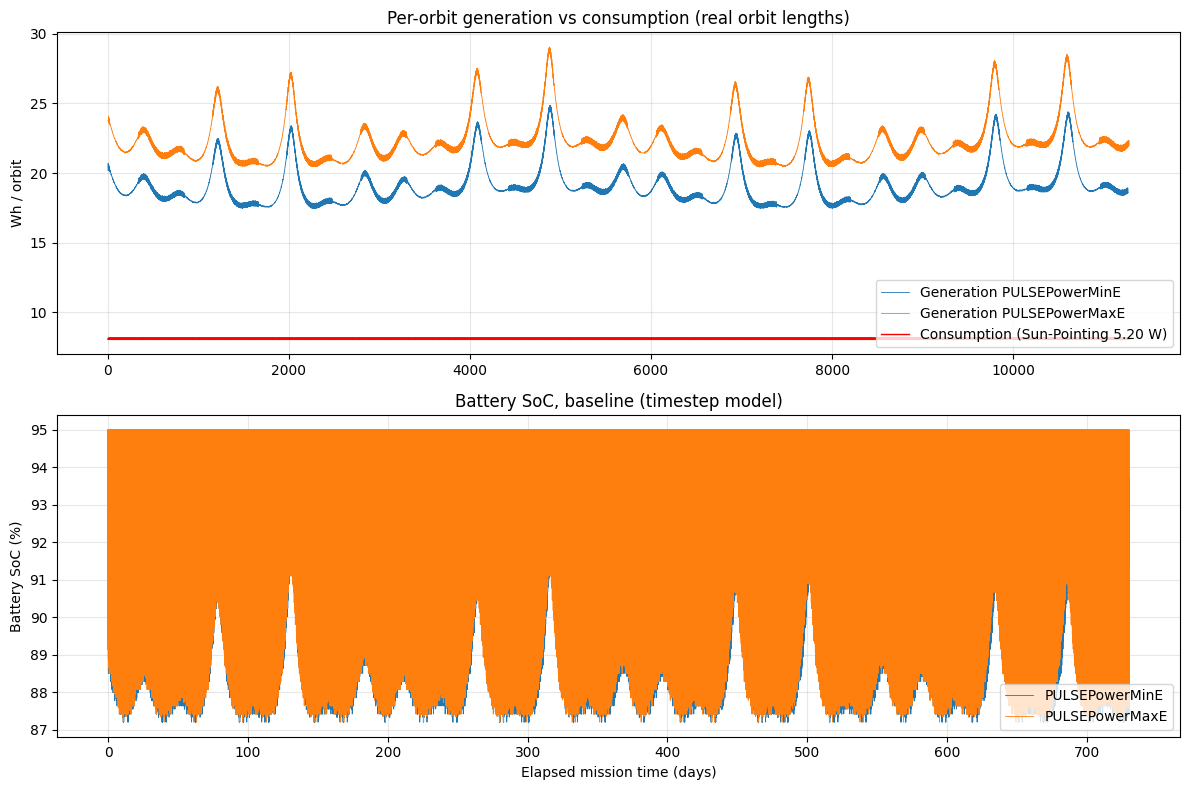

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=False)
for name, s in summaries.items():
    full = sim.orbit_flags(s)["full"]
    axes[0].plot(s[full, 0], s[full, sim.COL["generation_wh"]], lw=0.6, label=f"Generation {name}")
axes[0].plot(s[full, 0], s[full, sim.COL["consumption_wh"]], color="red", lw=1.0, label="Consumption (Sun-Pointing 5.20 W)")
axes[0].set_ylabel("Wh / orbit"); axes[0].set_title("Per-orbit generation vs consumption (real orbit lengths)")
axes[0].grid(alpha=0.3); axes[0].legend(loc="lower right")
for name, r in results.items():
    sim.plot_soc(r, ax=axes[1], label=name)
axes[1].set_title("Battery SoC, baseline (timestep model)")
plt.tight_layout(); plt.show()


## 1. Battery threshold

Thresholds: 95 % charge cap, 33 % recovery/DoD, 20 % operational warning, **15 % safe-mode entry (ConOps)**, 10 % hard floor.
Four load cases are compared because the baseline (5.20 W Sun-Pointing) is optimistic:

| case | what it is |
|---|---|
| baseline | Sun-Pointing all the time (engine baseline) |
| 9.10 W constant | master-budget orbit-average (13.65 Wh per 90 min) |
| realistic ops | detumble 6 h, RF pass every 3rd orbit, payload acquisition 10 min/day in eclipse, calibration 10 min/day in sun, safe mode < 15 % |
| stress | payload acquisition + calibration + RF **every orbit** |

In [6]:
scenarios = {
    "baseline": dict(schedule=sim.BASELINE),
    "9.10 W constant": dict(constant_load_w=9.10),
    "realistic ops": dict(schedule=sim.OpsSchedule()),
    "stress (every orbit)": dict(schedule=sim.PAYLOAD_EVERY_ORBIT),
}
scenario_results, scenario_metrics = {}, {}
for case, d in data.items():
    for scen, kw in scenarios.items():
        r = sim.run_csv_mission_simulation(case, csv_data=d, state_powers=state_powers, **kw)
        scenario_results[(case, scen)] = r
        scenario_metrics[(case, scen)] = sim.mission_metrics(r)

print(f"{'case':<16}{'scenario':<22}{'min SoC %':>10}{'final %':>9}{'h<33%':>7}{'h<20%':>7}{'h<15%':>7}{'max DoD/orbit %':>17}{'cons Wh/orb':>12}{'min net Wh/orb':>15}")
for (case, scen), m in scenario_metrics.items():
    print(f"{case:<16}{scen:<22}{m['min_soc_percent']:>10.1f}{m['final_soc_percent']:>9.1f}{m['hours_below_33']:>7.0f}"
          f"{m['hours_below_20']:>7.0f}{m['hours_below_15']:>7.0f}{m['max_orbit_dod_percent']:>17.1f}{m['mean_cons_wh_orbit']:>12.2f}{m['min_net_wh_orbit']:>15.2f}")


case            scenario               min SoC %  final %  h<33%  h<20%  h<15%  max DoD/orbit % cons Wh/orb min net Wh/orb
PULSEPowerMinE  baseline                    87.2     93.5      0      0      0              7.8        8.08           9.39
PULSEPowerMinE  9.10 W constant             81.3     92.2      0      0      0             13.7       14.15           3.30
PULSEPowerMinE  realistic ops               78.1     93.5      0      0      0             16.9        8.45           4.26
PULSEPowerMinE  stress (every orbit)        78.0     87.4      0      0      0             17.0       13.07           4.18
PULSEPowerMaxE  baseline                    87.2     90.2      0      0      0              7.8        8.08          12.35
PULSEPowerMaxE  9.10 W constant             81.3     86.7      0      0      0             13.7       14.14           6.24
PULSEPowerMaxE  realistic ops               78.4     89.9      0      0      0             16.6        8.44           7.19
PULSEPowerMaxE  

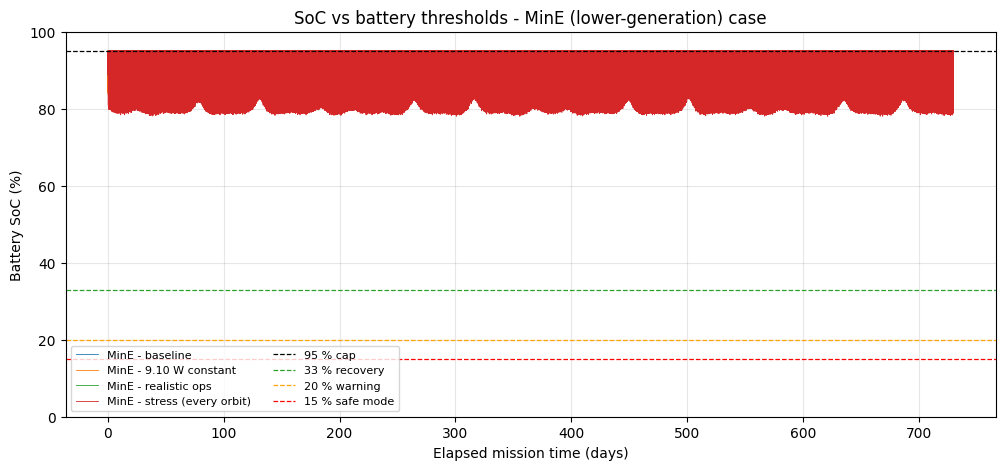

In [7]:
fig, ax = plt.subplots(figsize=(12, 5))
for scen in scenarios:
    r = scenario_results[("PULSEPowerMinE", scen)]
    sim.plot_soc(r, ax=ax, label=f"MinE - {scen}")
for frac, lab, c in [(0.95, "95 % cap", "k"), (0.33, "33 % recovery", "tab:green"),
                     (0.20, "20 % warning", "orange"), (0.15, "15 % safe mode", "red")]:
    ax.axhline(100 * frac, ls="--", lw=0.9, color=c, label=lab)
ax.set_ylim(0, 100); ax.set_title("SoC vs battery thresholds - MinE (lower-generation) case")
ax.legend(loc="lower left", ncol=2, fontsize=8); plt.show()


## 2. Anomaly / outlier analysis (per-orbit net energy, full orbits only)

full orbits analysed : 11268
median net energy    : 10.54 Wh/orbit  (MAD 0.63)
anomalous orbits     : 1258  (11.16 %)
lowest net orbit     : orbit 2256, 4.26 Wh (eclipse 36 min)
Any orbit with negative net energy? False


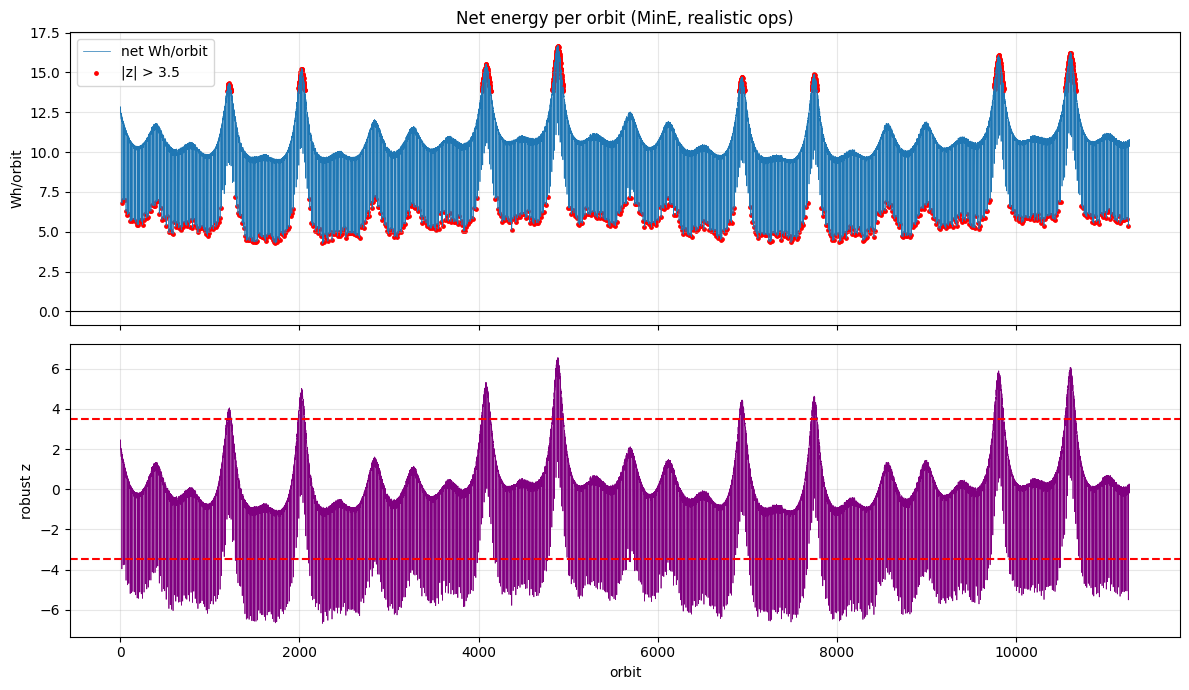

In [8]:
# Robust z-score on per-orbit net energy for the MinE realistic-ops run.
s = sim.summarize_by_orbit(scenario_results[("PULSEPowerMinE", "realistic ops")])
full = sim.orbit_flags(s)["full"]
s = s[full]
net_energy = s[:, sim.COL["generation_wh"]] - s[:, sim.COL["consumption_wh"]]
median_net = float(np.median(net_energy))
mad_net = float(np.median(np.abs(net_energy - median_net)) + 1e-9)
robust_z = 0.6745 * (net_energy - median_net) / mad_net
threshold = 3.5
anomaly = np.abs(robust_z) > threshold

print(f"full orbits analysed : {len(net_energy)}")
print(f"median net energy    : {median_net:.2f} Wh/orbit  (MAD {mad_net:.2f})")
print(f"anomalous orbits     : {anomaly.sum()}  ({100 * anomaly.mean():.2f} %)")
print(f"lowest net orbit     : orbit {int(s[np.argmin(net_energy), 0])}, {net_energy.min():.2f} Wh "
      f"(eclipse {s[np.argmin(net_energy), sim.COL['eclipse_min']]:.0f} min)")
print("Any orbit with negative net energy?", bool((net_energy < 0).any()))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(s[:, 0], net_energy, lw=0.5, label="net Wh/orbit")
axes[0].scatter(s[anomaly, 0], net_energy[anomaly], s=6, color="red", label="|z| > 3.5")
axes[0].axhline(0, color="k", lw=0.8); axes[0].set_ylabel("Wh/orbit"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title("Net energy per orbit (MinE, realistic ops)")
axes[1].plot(s[:, 0], robust_z, lw=0.5, color="purple"); axes[1].axhline(threshold, color="r", ls="--"); axes[1].axhline(-threshold, color="r", ls="--")
axes[1].set_ylabel("robust z"); axes[1].set_xlabel("orbit"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()


## 3. Consumption statistics by state

In [9]:
r = scenario_results[("PULSEPowerMinE", "realistic ops")]
states, inv = np.unique(r["state_history"].astype(str), return_inverse=True)
hours = np.bincount(inv, weights=r["dt_hours"])
energy = np.bincount(inv, weights=r["consumption_wh"])
print(f"{'State':<24}{'Power (W)':>10}{'time share':>12}{'energy share':>14}")
for k, st in enumerate(states):
    print(f"{st:<24}{state_powers[st]:>10.2f}{100 * hours[k] / hours.sum():>11.2f}%{100 * energy[k] / energy.sum():>13.2f}%")
print(f"\nOrbit-average load (realistic ops): {energy.sum() / hours.sum():.2f} W")


State                    Power (W)  time share  energy share
Detumble                      5.01       0.03%         0.03%
Payload - Acquisition        23.55       0.73%         3.17%
Payload - Calibration        14.59       0.73%         1.96%
RF Pass                       5.98       3.73%         4.10%
Sun-Pointing                  5.20      94.78%        90.73%

Orbit-average load (realistic ops): 5.43 W


## 4. Solar acquisition statistics

[PULSEPowerMinE] generation per full orbit mean/std/min/max = 19.02 / 1.33 / 17.45 / 24.84 Wh
[PULSEPowerMaxE] generation per full orbit mean/std/min/max = 22.22 / 1.52 / 20.44 / 29.05 Wh


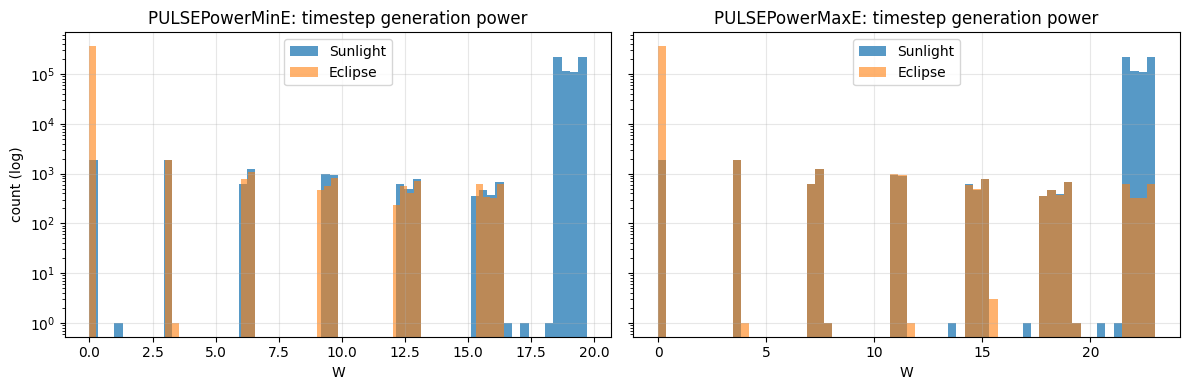

In [10]:
for name, s in summaries.items():
    full = sim.orbit_flags(s)["full"]
    g = s[full, sim.COL["generation_wh"]]
    print(f"[{name}] generation per full orbit mean/std/min/max = {g.mean():.2f} / {g.std(ddof=1):.2f} / {g.min():.2f} / {g.max():.2f} Wh")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, d) in zip(axes, data.items()):
    p = d["generation_w"]; sh = d["in_shadow"]
    ax.hist(p[sh == 0], bins=60, alpha=0.75, label="Sunlight")
    ax.hist(p[sh == 1], bins=60, alpha=0.6, label="Eclipse")
    ax.set_title(f"{name}: timestep generation power"); ax.set_xlabel("W"); ax.set_yscale("log"); ax.grid(alpha=0.3); ax.legend()
axes[0].set_ylabel("count (log)")
plt.tight_layout(); plt.show()


## 5. Orbit / insertion requirements evidence

This section turns the simulation into answers for the NASA LSP *Orbital Parameter Requirements* chart and the PPRR *Orbit/Insertion Requirements* slide.

### 5a. What orbit is the STK power run actually using?

In [11]:
orbit_ref = {}
for name, s in summaries.items():
    orbit_ref[name] = sim.estimate_orbit_from_profile(s)
    o = orbit_ref[name]
    print(f"[{name}] mean period {o['mean_period_min']:.2f} min -> a = {o['semi_major_axis_km']:.0f} km, "
          f"altitude ~ {o['altitude_km']:.0f} km (circular)")
    print(f"           eclipse {o['eclipse_min_min']:.0f}-{o['eclipse_max_min']:.0f} min (mean {o['eclipse_mean_min']:.1f}), "
          f"sunlight {o['sunlight_min_min']:.0f}-{o['sunlight_max_min']:.0f} min, full-sun orbits: {o['full_sun_orbits']}")
    print(f"           shortest eclipse -> beta_max ~ {o['beta_max_deg_est']:.1f} deg -> inclination ~ {o['inclination_deg_est']:.1f} deg")


[PULSEPowerMinE] mean period 93.29 min -> a = 6822 km, altitude ~ 443 km (circular)
           eclipse 17-37 min (mean 33.2), sunlight 56-76 min, full-sun orbits: 0
           shortest eclipse -> beta_max ~ 65.0 deg -> inclination ~ 41.6 deg
[PULSEPowerMaxE] mean period 93.20 min -> a = 6817 km, altitude ~ 439 km (circular)
           eclipse 18-37 min (mean 33.3), sunlight 57-76 min, full-sun orbits: 0
           shortest eclipse -> beta_max ~ 64.5 deg -> inclination ~ 41.1 deg


### 5b. Inclination: why 37° is the floor and ~42–48° is the sweet spot

* Geometry: the Chicago OGS (41.79° N) only sees a *viable* optical pass (elevation ≥ 30°, Optical Passes guide) if the ground track reaches latitude − ground-range.
* Access trade study (STK › `ogs_summary_stats.csv`, 500 km circular, 3 months, viable OGS passes): values are copied below so this notebook runs offline.

h = 400 km: ground range at 30 deg el = 5.42 deg -> minimum inclination for a viable OGS pass = 36.4 deg; slant range at 30 deg = 739 km
h = 450 km: ground range at 30 deg el = 6.01 deg -> minimum inclination for a viable OGS pass = 35.8 deg; slant range at 30 deg = 825 km
h = 500 km: ground range at 30 deg el = 6.58 deg -> minimum inclination for a viable OGS pass = 35.2 deg; slant range at 30 deg = 910 km
h = 550 km: ground range at 30 deg el = 7.13 deg -> minimum inclination for a viable OGS pass = 34.7 deg; slant range at 30 deg = 993 km


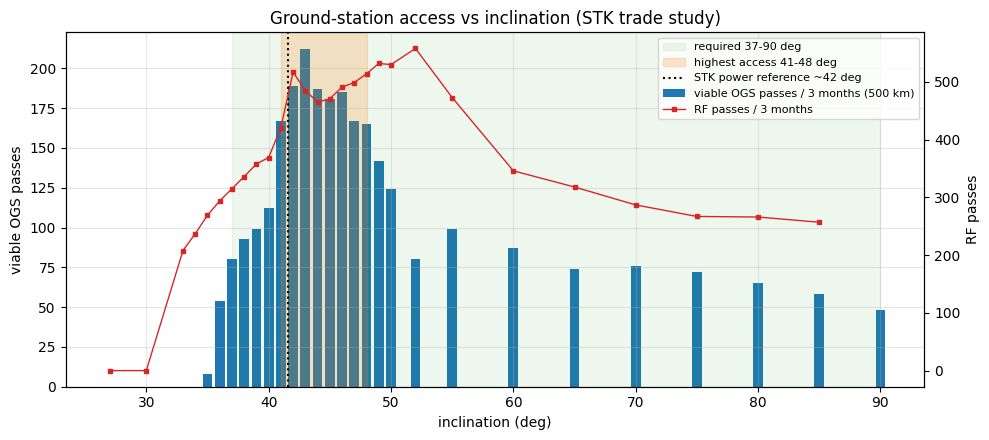

In [12]:
for h in [400, 450, 500, 550]:
    print(f"h = {h} km: ground range at 30 deg el = {sim.ground_range_deg(h, 30):.2f} deg -> "
          f"minimum inclination for a viable OGS pass = {sim.min_inclination_for_station(h, 30):.1f} deg; "
          f"slant range at 30 deg = {sim.slant_range_km(h, 30):.0f} km")

# STK access trade study, 500 km circular, 3 months (Drive > STK > ogs_summary_stats.csv, Apr 29 2026)
inc_deg  = np.array([27, 30, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 52, 55, 60, 65, 70, 75, 80, 85, 90])
ogs_pass = np.array([ 0,  0,  0,  0,  8, 54, 80, 93, 99,112,167,189,212,187,181,185,167,165,142,124, 80, 99, 87, 74, 76, 72, 65, 58, 48])
rf_pass  = np.array([ 0,  0,208,237,269,294,315,336,358,369,421,517,485,465,471,491,499,514,532,530,558,473,346,318,287,267,266,257,np.nan])
gap_max_h= np.array([ 0,  0,  0,  0,1012,799,680,609,609,609,609,607,489,537,608,609,609,584,513,513,513,513,490, 96, 96, 96,106, 73,873])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(inc_deg, ogs_pass, width=0.8, color="tab:blue", label="viable OGS passes / 3 months (500 km)")
ax.axvspan(37, 90, color="tab:green", alpha=0.08, label="required 37-90 deg")
ax.axvspan(41, 48, color="tab:orange", alpha=0.20, label="highest access 41-48 deg")
ax.axvline(41.6, color="k", ls=":", label="STK power reference ~42 deg")
ax2 = ax.twinx(); ax2.plot(inc_deg, rf_pass, "s-", color="tab:red", ms=3, lw=1, label="RF passes / 3 months"); ax2.set_ylabel("RF passes")
ax.set_xlabel("inclination (deg)"); ax.set_ylabel("viable OGS passes"); ax.grid(alpha=0.3)
ax.set_title("Ground-station access vs inclination (STK trade study)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(fig_dir / "access_vs_inclination.png", dpi=200); plt.show()


### 5c / 5d. Altitude and eccentricity: is any orbit inside 400–550 km acceptable?

A first-order propagator (two-body + J2 drift, cylindrical shadow) is used to compare circular and eccentric orbits.
It is **validated first** against the STK reference orbit, then generation is scaled as *mean STK sunlit power × sunlit minutes* (Sun-Pointing attitude ⇒ ~constant array power in sunlight).

In [13]:
p_sun = {name: reports[name]["mean_sunlit_power_w"] for name in reports}
ref = orbit_ref["PULSEPowerMinE"]

envelope_cases = [
    ("STK reference (validation)", ref["altitude_km"], ref["altitude_km"], ref["inclination_deg_est"]),
    ("400 km circular, 42 deg",   400, 400, 42.0),
    ("550 km circular, 42 deg",   550, 550, 42.0),
    ("400 x 550 km (e=0.011), 42 deg", 400, 550, 42.0),
    ("400 x 550 km, 37 deg",      400, 550, 37.0),
    ("400 x 550 km, 51.6 deg (ISS)", 400, 550, 51.6),
    ("400 x 550 km, 90 deg",      400, 550, 90.0),
]
envelope = {}
loads = {"5.20 W Sun-Pointing": 5.20, "9.10 W master budget": 9.10}
print(f"{'case':<34}{'e':>7}{'T min':>8}{'ecl min':>9}{'ecl mean':>9}{'ecl max':>9}{'full-sun':>9}{'worst gen Wh':>13}{'worst net @9.1W':>16}")
for label, hp, ha, inc in envelope_cases:
    prop = sim.propagate_eclipse_profile(hp, ha, inc, days=365, dt_min=0.5)
    gen = p_sun["PULSEPowerMinE"] * prop["sunlight_min"] / 60.0          # Wh per orbit (MinE power level)
    net91 = gen - 9.10 * prop["period_min"] / 60.0
    envelope[label] = dict(prop=prop, gen=gen, net91=net91)
    print(f"{label:<34}{prop['e']:>7.4f}{prop['period_min'].mean():>8.2f}{prop['eclipse_min'].min():>9.1f}{prop['eclipse_min'].mean():>9.1f}"
          f"{prop['eclipse_min'].max():>9.1f}{(prop['eclipse_min'] < 0.5).sum():>9d}{gen.min():>13.2f}{net91.min():>16.2f}")

stk = summaries["PULSEPowerMinE"]; stk = stk[sim.orbit_flags(stk)["full"]]
print(f"\nSTK MinE truth: eclipse {stk[:,2].min():.0f}-{stk[:,2].max():.0f} min (mean {stk[:,2].mean():.1f}); "
      f"generation min {stk[:,4].min():.2f} Wh/orbit -> propagator agrees to within ~1-2 min of eclipse.")

# Worst-orbit intra-orbit depth of discharge (longest eclipse, payload pass in eclipse)
for cap in (40.0, 50.4):
    worst_ecl = max(v["prop"]["eclipse_min"].max() for v in envelope.values())
    dod_nom = 9.10 * worst_ecl / 60 / cap * 100
    dod_pl = (5.20 * (worst_ecl - 10) + state_powers["Payload - Acquisition"] * 10) / 60 / cap * 100
    print(f"battery {cap} Wh: longest eclipse {worst_ecl:.1f} min -> DoD {dod_nom:.1f} % at 9.10 W, "
          f"{dod_pl:.1f} % with a 10-min payload pass in eclipse")


case                                    e   T min  ecl min ecl mean  ecl max full-sun worst gen Wh worst net @9.1W


STK reference (validation)         0.0000   93.29     18.5     33.2     36.5        0        17.92            3.74


400 km circular, 42 deg            0.0000   92.40     19.5     33.5     36.5        0        17.45            3.49


550 km circular, 42 deg            0.0000   95.49     10.5     32.3     36.0        0        18.55            4.14


400 x 550 km (e=0.011), 42 deg     0.0109   93.94     17.5     32.8     36.0        0        18.08            3.90


400 x 550 km, 37 deg               0.0109   93.90     22.5     33.5     36.5        0        17.92            3.74


400 x 550 km, 51.6 deg (ISS)       0.0109   94.03      0.0     30.9     36.5      210        18.08            3.82


400 x 550 km, 90 deg               0.0109   94.23      6.5     28.9     36.5        0        18.08            3.82

STK MinE truth: eclipse 17-37 min (mean 33.2); generation min 17.45 Wh/orbit -> propagator agrees to within ~1-2 min of eclipse.
battery 40.0 Wh: longest eclipse 36.5 min -> DoD 13.8 % at 9.10 W, 15.6 % with a 10-min payload pass in eclipse
battery 50.4 Wh: longest eclipse 36.5 min -> DoD 11.0 % at 9.10 W, 12.3 % with a 10-min payload pass in eclipse


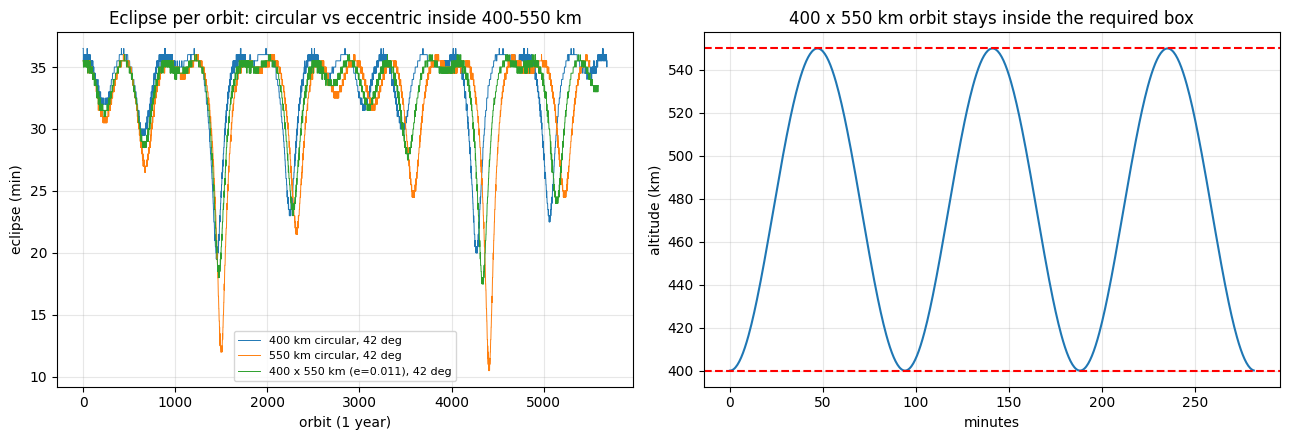

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for label in ["400 km circular, 42 deg", "550 km circular, 42 deg", "400 x 550 km (e=0.011), 42 deg"]:
    e = envelope[label]["prop"]["eclipse_min"]
    axes[0].plot(e, lw=0.7, label=label)
axes[0].set_xlabel("orbit (1 year)"); axes[0].set_ylabel("eclipse (min)"); axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)
axes[0].set_title("Eclipse per orbit: circular vs eccentric inside 400-550 km")
alt = envelope["400 x 550 km (e=0.011), 42 deg"]["prop"]["altitude_km"][: int(3 * 94 / 0.5)]
axes[1].plot(np.arange(len(alt)) * 0.5, alt); axes[1].axhline(400, ls="--", c="r"); axes[1].axhline(550, ls="--", c="r")
axes[1].set_xlabel("minutes"); axes[1].set_ylabel("altitude (km)"); axes[1].set_title("400 x 550 km orbit stays inside the required box")
axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(fig_dir / "eccentricity_check.png", dpi=200); plt.show()


### 5e. Insertion date: does the season of deployment change the power result?

In [15]:
# Start the 1-year mission at each month of the 2-year STK profile (different beta-angle phase)
# with the realistic operations schedule, and record the minimum SoC.
start_month_min_soc = {}
for case, d in data.items():
    mins = []
    for k in range(12):
        idx = int(np.searchsorted(d["elapsed_days"], 30.4 * k))
        r = sim.run_csv_mission_simulation(case, csv_data=d, schedule=sim.OpsSchedule(), state_powers=state_powers, start_index=idx)
        n = int(np.searchsorted(r["elapsed_days"] - r["elapsed_days"][0], 365.0))
        mins.append(r["soc_percent"][:n].min())
    start_month_min_soc[case] = np.array(mins)
    print(f"{case}: min SoC over a 1-year mission, by start month offset 0..11 -> {np.round(mins, 1)}")


PULSEPowerMinE: min SoC over a 1-year mission, by start month offset 0..11 -> [78.1 78.4 78.3 78.2 78.3 78.1 78.4 78.5 78.4 78.3 78.2 78.1]


PULSEPowerMaxE: min SoC over a 1-year mission, by start month offset 0..11 -> [78.5 78.3 78.2 78.5 78.6 78.5 78.2 78.2 78.4 78.6 78.4 78.2]


### 5f. Handover → deployment: how low can the battery be at deployment?

ConOps: 45-min timer after deployment, antenna deploys if battery > 70 %, safe mode below 15 %.
The sweep below starts the mission at low SoC with the realistic schedule (detumble first) and measures recovery time.
*(Assumes the deployed-array STK generation; stowed-panel generation from the Boot-Config STK runs would lengthen recovery.)*

In [16]:
print(f"{'case':<16}{'battery':>9}{'SoC at deploy':>15}{'min SoC':>9}{'safe-mode entries':>19}{'hours to 90 %':>15}")
recovery = {}
for case, d in data.items():
    for cap in (40.0, 50.4):
        for init in (0.107, 0.15, 0.30, 0.50, 0.70, 0.90):
            r = sim.run_csv_mission_simulation(case, csv_data=d, schedule=sim.OpsSchedule(), state_powers=state_powers,
                                               initial_soc_fraction=init, battery_capacity_wh=cap)
            s = r["soc_percent"]
            hrs = r["elapsed_hours"][np.argmax(s >= 90)] - r["elapsed_hours"][0] if (s >= 90).any() else np.nan
            recovery[(case, cap, init)] = hrs
            print(f"{case:<16}{cap:>7.1f}Wh{100 * init:>14.1f}%{s.min():>9.1f}{r['safe_mode_entries']:>19d}{hrs:>15.1f}")

# Ground storage: time until the pack self-discharges from full charge (92.9 % at 8.2 V)
# to the 70 % antenna-deploy threshold.  Self-discharge rate is an ASSUMPTION for an
# 18650 NMC pack with inhibits open; replace with the EPS storage-test value.
for rate in (1.0, 2.0, 3.0):
    print(f"self-discharge {rate:.0f} %/month -> 92.9 % -> 70 % takes {(92.9 - 70) / rate:.0f} months")


case              battery  SoC at deploy  min SoC  safe-mode entries  hours to 90 %


PULSEPowerMinE     40.0Wh          10.7%     10.5                  1            3.5


PULSEPowerMinE     40.0Wh          15.0%     14.7                  1            2.7


PULSEPowerMinE     40.0Wh          30.0%     28.2                  0            2.6


PULSEPowerMinE     40.0Wh          50.0%     48.2                  0            2.0


PULSEPowerMinE     40.0Wh          70.0%     68.2                  0            0.8


... (15 outputs left out)

PULSEPowerMaxE     50.4Wh          30.0%     29.2                  0            3.0


PULSEPowerMaxE     50.4Wh          50.0%     49.2                  0            2.5


PULSEPowerMaxE     50.4Wh          70.0%     69.2                  0            1.3


PULSEPowerMaxE     50.4Wh          90.0%     81.8                  0            0.0
self-discharge 1 %/month -> 92.9 % -> 70 % takes 23 months
self-discharge 2 %/month -> 92.9 % -> 70 % takes 11 months
self-discharge 3 %/month -> 92.9 % -> 70 % takes 8 months


### 5g. Slide-ready summary

In [17]:
o = orbit_ref["PULSEPowerMinE"]
mE = scenario_metrics[("PULSEPowerMinE", "realistic ops")]
mS = scenario_metrics[("PULSEPowerMinE", "stress (every orbit)")]
ecc = envelope["400 x 550 km (e=0.011), 42 deg"]
print("REFERENCE ORBIT (from STK power data)")
print(f"  ~{o['altitude_km']:.0f} km circular, ~{o['inclination_deg_est']:.0f} deg, period {o['mean_period_min']:.1f} min, "
      f"eclipse {o['eclipse_min_min']:.0f}-{o['eclipse_max_min']:.0f} min, no full-sun orbits")
print("POWER")
print(f"  every orbit power-positive in both STK cases; min SoC {mE['min_soc_percent']:.0f} % (realistic ops), "
      f"{mS['min_soc_percent']:.0f} % (payload+RF every orbit); never below 33 %")
print("INCLINATION")
print(f"  OGS geometry floor {sim.min_inclination_for_station(550, 30):.1f}-{sim.min_inclination_for_station(400, 30):.1f} deg (550-400 km) -> 37 deg required floor; "
      "access peaks at 41-48 deg (165-212 viable passes / 3 mo vs 80 at 37 deg)")
print("ECCENTRICITY")
print(f"  400 x 550 km (e = {ecc['prop']['e']:.4f}): eclipse {ecc['prop']['eclipse_min'].min():.0f}-{ecc['prop']['eclipse_min'].max():.0f} min, "
      f"worst-orbit net {ecc['net91'].min():.1f} Wh at 9.10 W -> acceptable")
print("INSERTION DATE")
print(f"  min SoC varies only {min(v.min() for v in start_month_min_soc.values()):.1f}-{max(v.max() for v in start_month_min_soc.values()):.1f} % "
      "across start months -> no power constraint on date")
print("DEPLOYMENT SoC")
print(f"  even at 10.7 % SoC on deployment the battery is back above 90 % within "
      f"{max(v for k, v in recovery.items() if k[2] == 0.107):.1f} h (deployed arrays)")


REFERENCE ORBIT (from STK power data)
  ~443 km circular, ~42 deg, period 93.3 min, eclipse 17-37 min, no full-sun orbits
POWER
  every orbit power-positive in both STK cases; min SoC 78 % (realistic ops), 78 % (payload+RF every orbit); never below 33 %
INCLINATION
  OGS geometry floor 34.7-36.4 deg (550-400 km) -> 37 deg required floor; access peaks at 41-48 deg (165-212 viable passes / 3 mo vs 80 at 37 deg)
ECCENTRICITY
  400 x 550 km (e = 0.0109): eclipse 18-36 min, worst-orbit net 3.9 Wh at 9.10 W -> acceptable
INSERTION DATE
  min SoC varies only 78.1-78.6 % across start months -> no power constraint on date
DEPLOYMENT SoC
  even at 10.7 % SoC on deployment the battery is back above 90 % within 3.8 h (deployed arrays)
